In [4]:
import os
import random
import pickle
import time
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score
)

from sklearn.manifold import TSNE

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

print("Seed:", SEED)

Seed: 42


In [6]:
CONFIG = {
    "DATA_DIR": "/kaggle/input/notebooks/ssuhaass/ksvnote1/processed_data_ksc",

    "PATCH_SIZE": 9,
    "PCA_COMPONENTS": 30,
    "NUM_CLASSES": 13,

    "BATCH_SIZE": 32,
    "EPOCHS": 150,

    "LEARNING_RATE": 3e-4,
    "WEIGHT_DECAY": 1e-4,

    "DROPOUT": 0.3,

    "LSTM_HIDDEN": 64,
    "LSTM_LAYERS": 2,

    "NUM_WORKERS": 2,

    "PATIENCE": 20,
    "GRAD_CLIP": 1.0,
    "LABEL_SMOOTHING" : 0.05,

    "SEED": 42
}

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Data directory:", CONFIG["DATA_DIR"])
print("Device:", DEVICE)

Data directory: /kaggle/input/notebooks/ssuhaass/ksvnote1/processed_data_ksc
Device: cpu


In [7]:
DATA_DIR = CONFIG["DATA_DIR"]

train_data = np.load(
    os.path.join(DATA_DIR, "train.npz")
)

val_data = np.load(
    os.path.join(DATA_DIR, "validation.npz")
)

test_data = np.load(
    os.path.join(DATA_DIR, "test.npz")
)

X_train = train_data["X"]
y_train = train_data["y"]

X_val = val_data["X"]
y_val = val_data["y"]

X_test = test_data["X"]
y_test = test_data["y"]

print("Training:")
print(X_train.shape, y_train.shape)

print("\nValidation:")
print(X_val.shape, y_val.shape)

print("\nTesting:")
print(X_test.shape, y_test.shape)

Training:
(260, 9, 9, 30) (260,)

Validation:
(260, 9, 9, 30) (260,)

Testing:
(4691, 9, 9, 30) (4691,)


In [8]:
print("Train labels:", np.unique(y_train))
print("Val labels  :", np.unique(y_val))
print("Test labels :", np.unique(y_test))

assert y_train.min() >= 0
assert y_train.max() < CONFIG["NUM_CLASSES"]

assert y_val.min() >= 0
assert y_val.max() < CONFIG["NUM_CLASSES"]

assert y_test.min() >= 0
assert y_test.max() < CONFIG["NUM_CLASSES"]

print("\nLabel verification passed.")

Train labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]
Val labels  : [ 0  1  2  3  4  5  6  7  8  9 10 11 12]
Test labels : [ 0  1  2  3  4  5  6  7  8  9 10 11 12]

Label verification passed.


In [9]:
class KSCDataset(Dataset):

    def __init__(self, X, y, augment=False):
        self.X = torch.from_numpy(
            X.astype(np.float32)
        )
        self.y = torch.from_numpy(
            y.astype(np.int64)
        )
        self.augment = augment

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):

        x = self.X[index]
        y = self.y[index]

        if self.augment:

            # Horizontal flip
            if torch.rand(1).item() < 0.5:
                x = torch.flip(x, dims=[0])

            # Vertical flip
            if torch.rand(1).item() < 0.5:
                x = torch.flip(x, dims=[1])

            # Random 90° rotation
            k = torch.randint(0, 4, (1,)).item()

            if k > 0:
                x = torch.rot90(
                    x,
                    k=k,
                    dims=[0, 1]
                )

        return x, y

In [10]:
train_dataset = KSCDataset(
    X_train,
    y_train,
    augment=True
)

val_dataset = KSCDataset(
    X_val,
    y_val,
    augment=False
)

test_dataset = KSCDataset(
    X_test,
    y_test,
    augment=False
)

print("Train dataset:", len(train_dataset))
print("Val dataset  :", len(val_dataset))
print("Test dataset :", len(test_dataset))

Train dataset: 260
Val dataset  : 260
Test dataset : 4691


In [11]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("DataLoaders created.")

DataLoaders created.


In [12]:
class_counts = np.bincount(
    y_train,
    minlength=CONFIG["NUM_CLASSES"]
)

class_weights = (
    len(y_train) /
    (
        CONFIG["NUM_CLASSES"] *
        np.maximum(class_counts, 1)
    )
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(DEVICE)

print("Class weights:")
print(class_weights)

Class weights:
tensor([0.5263, 1.6667, 1.5385, 1.5385, 2.5000, 1.8182, 4.0000, 0.9091, 0.7692,
        1.0000, 0.9524, 0.8000, 0.4348])


In [13]:
class Residual3DBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):

        super().__init__()

        self.conv1 = nn.Conv3d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm3d(
            out_channels
        )

        self.conv2 = nn.Conv3d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm3d(
            out_channels
        )

        if in_channels != out_channels:

            self.shortcut = nn.Sequential(
                nn.Conv3d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    bias=False
                ),

                nn.BatchNorm3d(
                    out_channels
                )
            )

        else:

            self.shortcut = nn.Identity()

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):

        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity

        out = self.relu(out)

        return out

In [14]:
class SEBlock(nn.Module):

    def __init__(
        self,
        channels,
        reduction=8
    ):

        super().__init__()

        reduced_channels = max(
            channels // reduction,
            1
        )

        self.pool = nn.AdaptiveAvgPool3d(
            1
        )

        self.fc = nn.Sequential(

            nn.Linear(
                channels,
                reduced_channels
            ),

            nn.ReLU(inplace=True),

            nn.Linear(
                reduced_channels,
                channels
            ),

            nn.Sigmoid()
        )

    def forward(self, x):

        batch_size, channels, _, _, _ = x.shape

        weights = self.pool(x)

        weights = weights.view(
            batch_size,
            channels
        )

        weights = self.fc(weights)

        weights = weights.view(
            batch_size,
            channels,
            1,
            1,
            1
        )

        return x * weights

In [15]:
class SpectralAttention(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.score = nn.Sequential(

            nn.Linear(
                input_dim,
                input_dim
            ),

            nn.Tanh(),

            nn.Linear(
                input_dim,
                1
            )
        )

    def forward(self, x):

        # x:
        # (batch, sequence, features)

        scores = self.score(x)

        # (batch, sequence, 1)

        weights = torch.softmax(
            scores,
            dim=1
        )

        weighted = x * weights

        context = weighted.sum(
            dim=1
        )

        return context, weights

In [16]:
class CNN_BiLSTM_Attention(nn.Module):

    def __init__(self):

        super().__init__()

        self.cnn1 = Residual3DBlock(
            in_channels=1,
            out_channels=16
        )

        self.cnn2 = Residual3DBlock(
            in_channels=16,
            out_channels=32
        )

        self.se = SEBlock(
            channels=32,
            reduction=8
        )

        self.pool = nn.AdaptiveAvgPool3d(
            (
                CONFIG["PCA_COMPONENTS"],
                1,
                1
            )
        )

        self.bilstm = nn.LSTM(
            input_size=32,
            hidden_size=CONFIG["LSTM_HIDDEN"],
            num_layers=CONFIG["LSTM_LAYERS"],
            batch_first=True,
            bidirectional=True,
            dropout=CONFIG["DROPOUT"]
        )

        self.attention = SpectralAttention(
            CONFIG["LSTM_HIDDEN"] * 2
        )

        self.dropout = nn.Dropout(
            CONFIG["DROPOUT"]
        )

        self.classifier = nn.Linear(
            CONFIG["LSTM_HIDDEN"] * 2,
            CONFIG["NUM_CLASSES"]
        )

    def forward(self, x):

        # Input:
        # (B, H, W, C)

        x = x.permute(
            0, 3, 1, 2
        )

        # (B, C, H, W)

        x = x.unsqueeze(1)

        # (B, 1, C, H, W)

        x = self.cnn1(x)

        # (B, 16, C, H, W)

        x = self.cnn2(x)

        # (B, 32, C, H, W)

        x = self.se(x)

        # SE enhanced features

        x = self.pool(x)

        # (B, 32, PCA, 1, 1)

        x = x.squeeze(-1).squeeze(-1)

        # (B, 32, PCA)

        x = x.permute(
            0, 2, 1
        )

        # (B, PCA, 32)

        x, _ = self.bilstm(x)

        # (B, PCA, 128)

        x, attention_weights = self.attention(x)

        # (B, 128)

        x = self.dropout(x)

        logits = self.classifier(x)

        return logits, attention_weights

In [17]:
model = CNN_BiLSTM_Attention().to(DEVICE)

print(model)

CNN_BiLSTM_Attention(
  (cnn1): Residual3DBlock(
    (conv1): Conv3d(1, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
    (bn1): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv2): Conv3d(16, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
    (bn2): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (shortcut): Sequential(
      (0): Conv3d(1, 16, kernel_size=(1, 1, 1), stride=(1, 1, 1), bias=False)
      (1): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (relu): ReLU(inplace=True)
  )
  (cnn2): Residual3DBlock(
    (conv1): Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
    (bn1): BatchNorm3d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv2): Conv3d(32, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
    (bn2): Bat

In [18]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters    :", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

Total parameters    : 217,746
Trainable parameters: 217,746


In [19]:
sample_batch, sample_labels = next(
    iter(train_loader)
)

sample_batch = sample_batch.to(DEVICE)

with torch.no_grad():

    output, attention_weights = model(
        sample_batch
    )

print("Input shape:")
print(sample_batch.shape)

print("\nOutput shape:")
print(output.shape)

print("\nAttention shape:")
print(attention_weights.shape)

Input shape:
torch.Size([32, 9, 9, 30])

Output shape:
torch.Size([32, 13])

Attention shape:
torch.Size([32, 30, 1])


In [20]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

print("Loss function:", criterion)

Loss function: CrossEntropyLoss()


In [21]:
optimizer = optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

print(optimizer)

AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0003
    maximize: False
    weight_decay: 0.0001
)


In [22]:
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=150,
    eta_min=1e-6
)

print("CosineAnnealingLR initialized.")

CosineAnnealingLR initialized.


In [23]:
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

amp_enabled = torch.cuda.is_available()

print("AMP enabled:", torch.cuda.is_available())

AMP enabled: False


In [24]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for X, y in loader:

        X = X.to(
            device,
            non_blocking=True
        )

        y = y.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.autocast(
            device_type=device.type,
            enabled=device.type == "cuda"
        ):

            logits, _ = model(X)

            loss = criterion(
                logits,
                y
            )

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            CONFIG["GRAD_CLIP"]
        )

        scaler.step(optimizer)
        scaler.update()

        running_loss += (
            loss.item() * X.size(0)
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        correct += (
            predictions == y
        ).sum().item()

        total += y.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [25]:
def validate_one_epoch(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for X, y in loader:

            X = X.to(
                device,
                non_blocking=True
            )

            y = y.to(
                device,
                non_blocking=True
            )

            with torch.autocast(
                device_type=device.type,
                enabled=device.type == "cuda"
            ):

                logits, _ = model(X)

                loss = criterion(
                    logits,
                    y
                )

            running_loss += (
                loss.item() * X.size(0)
            )

            predictions = torch.argmax(
                logits,
                dim=1
            )

            correct += (
                predictions == y
            ).sum().item()

            total += y.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [26]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "learning_rate": []
}

best_val_loss = float("inf")
best_epoch = 0
patience_counter = 0

best_model_state = None

checkpoint_path = "/kaggle/working/ksc_best_checkpoint.pth"

print("=" * 70)
print("STARTING KSC MODEL TRAINING")
print("=" * 70)

start_time = time.time()

for epoch in range(1, CONFIG["EPOCHS"] + 1):

    epoch_start = time.time()

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        scaler,
        DEVICE
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion,
        DEVICE
    )

    scheduler.step()

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["train_accuracy"].append(
        train_acc
    )

    history["val_accuracy"].append(
        val_acc
    )

    history["learning_rate"].append(
        current_lr
    )

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch [{epoch:03d}/{CONFIG['EPOCHS']}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc*100:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc*100:.2f}% "
        f"| LR: {current_lr:.7f} "
        f"| Time: {epoch_time:.1f}s"
    )

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch
        patience_counter = 0

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": val_loss,
                "val_accuracy": val_acc,
                "config": CONFIG
            },
            checkpoint_path
        )

        print("  → Best model saved.")

    else:

        patience_counter += 1

        print(
            f"  → Patience: "
            f"{patience_counter}/"
            f"{CONFIG['PATIENCE']}"
        )

    if patience_counter >= CONFIG["PATIENCE"]:

        print("\nEarly stopping triggered.")
        break


total_time = time.time() - start_time

print("\nTraining completed.")
print(
    f"Total training time: "
    f"{total_time/60:.2f} minutes"
)

print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)

STARTING KSC MODEL TRAINING
Epoch [001/150] | Train Loss: 2.6223 | Train Acc: 14.23% | Val Loss: 2.6205 | Val Acc: 17.69% | LR: 0.0003000 | Time: 4.4s
  → Best model saved.
Epoch [002/150] | Train Loss: 2.6191 | Train Acc: 16.92% | Val Loss: 2.6169 | Val Acc: 18.46% | LR: 0.0002999 | Time: 4.5s
  → Best model saved.
Epoch [003/150] | Train Loss: 2.6113 | Train Acc: 18.46% | Val Loss: 2.6103 | Val Acc: 20.77% | LR: 0.0002997 | Time: 4.4s
  → Best model saved.
Epoch [004/150] | Train Loss: 2.6007 | Train Acc: 21.92% | Val Loss: 2.5909 | Val Acc: 21.54% | LR: 0.0002995 | Time: 4.5s
  → Best model saved.
Epoch [005/150] | Train Loss: 2.5707 | Train Acc: 22.31% | Val Loss: 2.5400 | Val Acc: 22.69% | LR: 0.0002992 | Time: 4.4s
  → Best model saved.
Epoch [006/150] | Train Loss: 2.5113 | Train Acc: 24.23% | Val Loss: 2.4455 | Val Acc: 26.15% | LR: 0.0002988 | Time: 4.4s
  → Best model saved.
Epoch [007/150] | Train Loss: 2.4399 | Train Acc: 26.92% | Val Loss: 2.3553 | Val Acc: 34.62% | LR: 0.

In [27]:
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

print(
    "Best model loaded from epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation accuracy:",
    f"{checkpoint['val_accuracy'] * 100:.2f}%"
)

Best model loaded from epoch: 130
Best validation accuracy: 95.77%


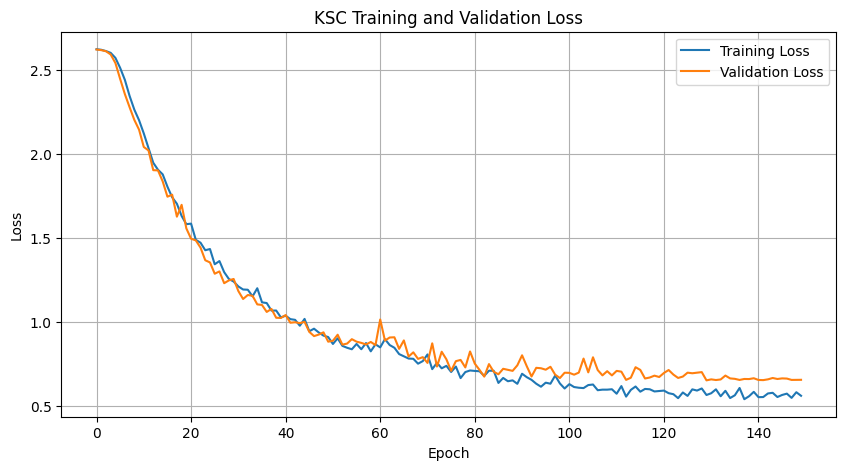

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "KSC Training and Validation Loss"
)

plt.legend()
plt.grid(True)

plt.show()

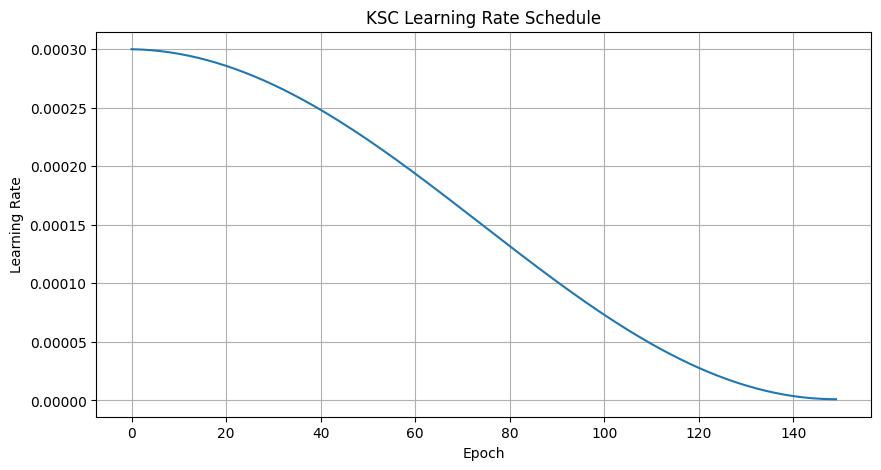

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["learning_rate"]
)

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")

plt.title(
    "KSC Learning Rate Schedule"
)

plt.grid(True)

plt.show()

In [30]:
history_df = pd.DataFrame(history)

history_path = (
    "/kaggle/working/"
    "ksc_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

print("Saved:", history_path)

Saved: /kaggle/working/ksc_training_history.csv


In [31]:
def predict_model(
    model,
    loader,
    device
):

    model.eval()

    all_predictions = []
    all_labels = []
    all_probabilities = []
    all_attention = []

    with torch.no_grad():

        for X, y in loader:

            X = X.to(
                device,
                non_blocking=True
            )

            logits, attention = model(X)

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            all_predictions.append(
                predictions.cpu().numpy()
            )

            all_labels.append(
                y.numpy()
            )

            all_probabilities.append(
                probabilities.cpu().numpy()
            )

            all_attention.append(
                attention.cpu().numpy()
            )

    y_true = np.concatenate(
        all_labels
    )

    y_pred = np.concatenate(
        all_predictions
    )

    y_prob = np.concatenate(
        all_probabilities
    )

    attention = np.concatenate(
        all_attention
    )

    return (
        y_true,
        y_pred,
        y_prob,
        attention
    )

In [32]:
y_true, y_pred, y_prob, attention_weights = predict_model(
    model,
    test_loader,
    DEVICE
)

print("y_true:", y_true.shape)
print("y_pred:", y_pred.shape)
print("y_prob:", y_prob.shape)
print("attention:", attention_weights.shape)

y_true: (4691,)
y_pred: (4691,)
y_prob: (4691, 13)
attention: (4691, 30, 1)


In [33]:
oa = accuracy_score(
    y_true,
    y_pred
)

print(
    f"Overall Accuracy: {oa * 100:.2f}%"
)

Overall Accuracy: 94.46%


In [34]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(
        CONFIG["NUM_CLASSES"]
    )
)

class_accuracy = (
    np.diag(cm) /
    np.maximum(
        cm.sum(axis=1),
        1
    )
)

aa = np.mean(
    class_accuracy
)

print(
    f"Average Accuracy: {aa * 100:.2f}%"
)

Average Accuracy: 91.25%


In [35]:
precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print(
    f"Macro Precision: {precision:.4f}"
)

Macro Precision: 0.9177


In [36]:
recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print(
    f"Macro Recall: {recall:.4f}"
)

Macro Recall: 0.9125


In [37]:
recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print(
    f"Macro Recall: {recall:.4f}"
)

Macro Recall: 0.9125


In [38]:
macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print(
    f"Macro F1: {macro_f1:.4f}"
)

Macro F1: 0.9137


In [39]:
kappa = cohen_kappa_score(
    y_true,
    y_pred
)

print(
    f"Cohen Kappa: {kappa:.4f}"
)

Cohen Kappa: 0.9382


In [40]:
print("=" * 60)
print("KSC FINAL TEST RESULTS")
print("=" * 60)

print(
    f"Overall Accuracy : {oa * 100:.2f}%"
)

print(
    f"Average Accuracy : {aa * 100:.2f}%"
)

print(
    f"Precision        : {precision:.4f}"
)

print(
    f"Recall           : {recall:.4f}"
)

print(
    f"Macro F1         : {macro_f1:.4f}"
)

print(
    f"Cohen Kappa      : {kappa:.4f}"
)

print("=" * 60)

KSC FINAL TEST RESULTS
Overall Accuracy : 94.46%
Average Accuracy : 91.25%
Precision        : 0.9177
Recall           : 0.9125
Macro F1         : 0.9137
Cohen Kappa      : 0.9382


In [41]:
class_report = classification_report(
    y_true,
    y_pred,

    labels=np.arange(
        CONFIG["NUM_CLASSES"]
    ),

    target_names=[
        CLASS_NAMES
        for CLASS_NAMES in [
            "Scrub",
            "Willow swamp",
            "CP hammock",
            "Slash pine",
            "Oak/Broadleaf",
            "Hardwood",
            "Swamp",
            "Graminoid marsh",
            "Spartina marsh",
            "Cattail marsh",
            "Salt marsh",
            "Mud flats",
            "Water"
        ]
    ],

    digits=4,
    zero_division=0
)

print(class_report)

                 precision    recall  f1-score   support

          Scrub     0.9716    1.0000    0.9856       685
   Willow swamp     0.9548    0.9635    0.9591       219
     CP hammock     0.9136    0.9652    0.9387       230
     Slash pine     0.8023    0.6283    0.7047       226
  Oak/Broadleaf     0.6460    0.7172    0.6797       145
       Hardwood     0.8404    0.7633    0.8000       207
          Swamp     1.0000    1.0000    1.0000        95
Graminoid marsh     0.9556    1.0000    0.9773       387
 Spartina marsh     0.9398    1.0000    0.9689       468
  Cattail marsh     0.9199    0.9148    0.9174       364
     Salt marsh     1.0000    0.9761    0.9879       377
      Mud flats     0.9953    0.9338    0.9636       453
          Water     0.9905    1.0000    0.9952       835

       accuracy                         0.9446      4691
      macro avg     0.9177    0.9125    0.9137      4691
   weighted avg     0.9440    0.9446    0.9433      4691



In [42]:
report_path = (
    "/kaggle/working/"
    "ksc_classification_report.txt"
)

with open(
    report_path,
    "w"
) as f:

    f.write(class_report)

print("Saved:", report_path)

Saved: /kaggle/working/ksc_classification_report.txt


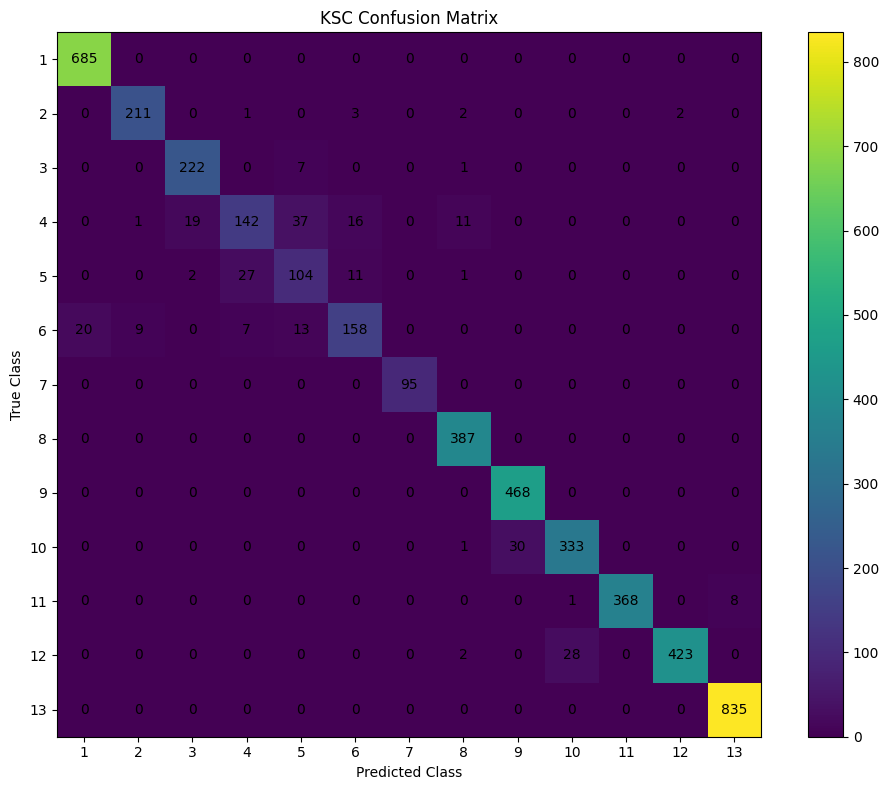

In [43]:
plt.figure(figsize=(10, 8))

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    "KSC Confusion Matrix"
)

plt.colorbar()

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(
    np.arange(13),
    np.arange(1, 14)
)

plt.yticks(
    np.arange(13),
    np.arange(1, 14)
)

for i in range(13):

    for j in range(13):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.show()

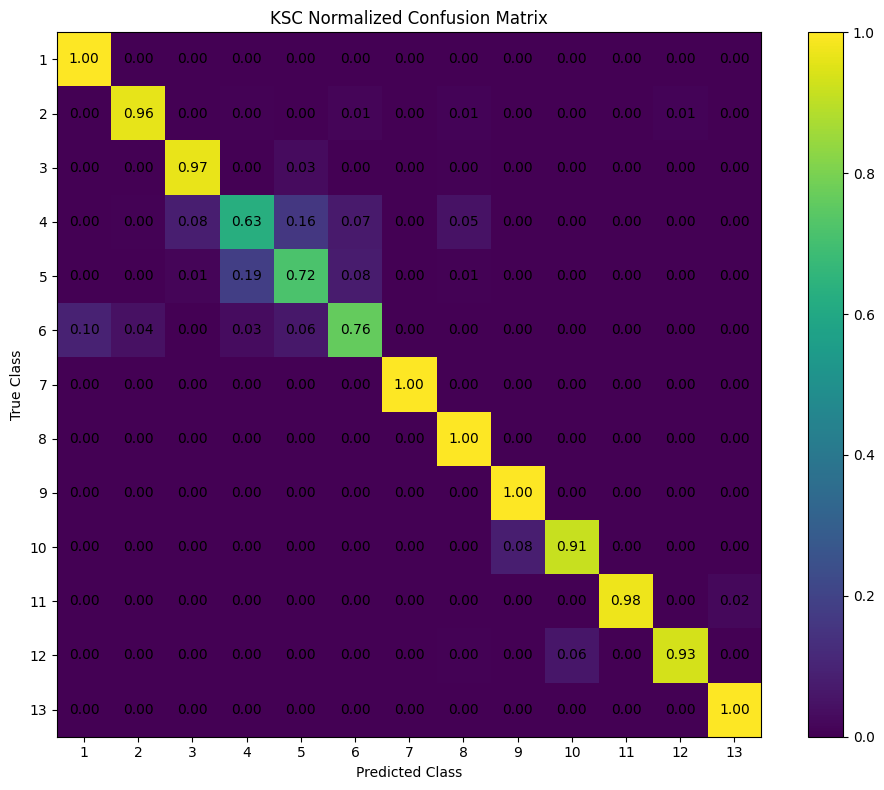

In [44]:
cm_normalized = (
    cm.astype(np.float64) /
    np.maximum(
        cm.sum(axis=1, keepdims=True),
        1
    )
)

plt.figure(figsize=(10, 8))

plt.imshow(
    cm_normalized,
    interpolation="nearest"
)

plt.title(
    "KSC Normalized Confusion Matrix"
)

plt.colorbar()

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(
    np.arange(13),
    np.arange(1, 14)
)

plt.yticks(
    np.arange(13),
    np.arange(1, 14)
)

for i in range(13):

    for j in range(13):

        plt.text(
            j,
            i,
            f"{cm_normalized[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.show()

In [45]:
print("=" * 60)
print("PER-CLASS ACCURACY")
print("=" * 60)

for i, acc in enumerate(
    class_accuracy
):

    print(
        f"Class {i + 1:2d} | "
        f"{CLASS_NAMES[i + 1]:20s} | "
        f"{acc * 100:.2f}%"
    )

PER-CLASS ACCURACY


NameError: name 'CLASS_NAMES' is not defined

In [46]:
metrics = {
    "Overall Accuracy": oa,
    "Average Accuracy": aa,
    "Macro Precision": precision,
    "Macro Recall": recall,
    "Macro F1": macro_f1,
    "Cohen Kappa": kappa
}

metrics_df = pd.DataFrame(
    [metrics]
)

metrics_df

,Overall Accuracy,Average Accuracy,Macro Precision,Macro Recall,Macro F1,Cohen Kappa
0,0.944575,0.912482,0.917663,0.912482,0.913702,0.938246


In [47]:
metrics_path = (
    "/kaggle/working/"
    "ksc_metrics.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False
)

print("Saved:", metrics_path)

Saved: /kaggle/working/ksc_metrics.csv


In [48]:
confidence = np.max(
    y_prob,
    axis=1
)

print(
    "Mean confidence:",
    confidence.mean()
)

print(
    "Minimum confidence:",
    confidence.min()
)

print(
    "Maximum confidence:",
    confidence.max()
)

Mean confidence: 0.85942066
Minimum confidence: 0.27014044
Maximum confidence: 0.9522398


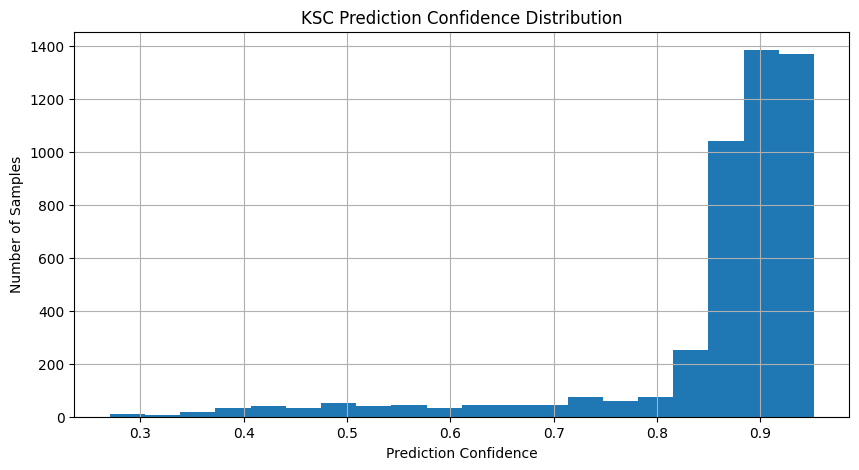

In [49]:
plt.figure(figsize=(10, 5))

plt.hist(
    confidence,
    bins=20
)

plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Samples")

plt.title(
    "KSC Prediction Confidence Distribution"
)

plt.grid(True)

plt.show()

In [50]:
def extract_features(
    model,
    loader,
    device
):

    model.eval()

    features = []
    labels = []

    with torch.no_grad():

        for X, y in loader:

            X = X.to(
                device,
                non_blocking=True
            )

            x = X.permute(
                0, 3, 1, 2
            )

            x = x.unsqueeze(1)

            x = model.cnn1(x)
            x = model.cnn2(x)
            x = model.se(x)

            x = model.pool(x)

            x = x.squeeze(-1).squeeze(-1)

            x = x.permute(
                0, 2, 1
            )

            x, _ = model.bilstm(x)

            x, _ = model.attention(x)

            features.append(
                x.cpu().numpy()
            )

            labels.append(
                y.numpy()
            )

    return (
        np.concatenate(features),
        np.concatenate(labels)
    )

In [51]:
features, feature_labels = extract_features(
    model,
    test_loader,
    DEVICE
)

print("Features:", features.shape)
print("Labels:", feature_labels.shape)

Features: (4691, 128)
Labels: (4691,)


In [52]:
tsne = TSNE(
    n_components=2,
    random_state=CONFIG["SEED"],
    perplexity=30,
    max_iter=1000
)

features_2d = tsne.fit_transform(
    features
)

print(
    "t-SNE shape:",
    features_2d.shape
)

t-SNE shape: (4691, 2)


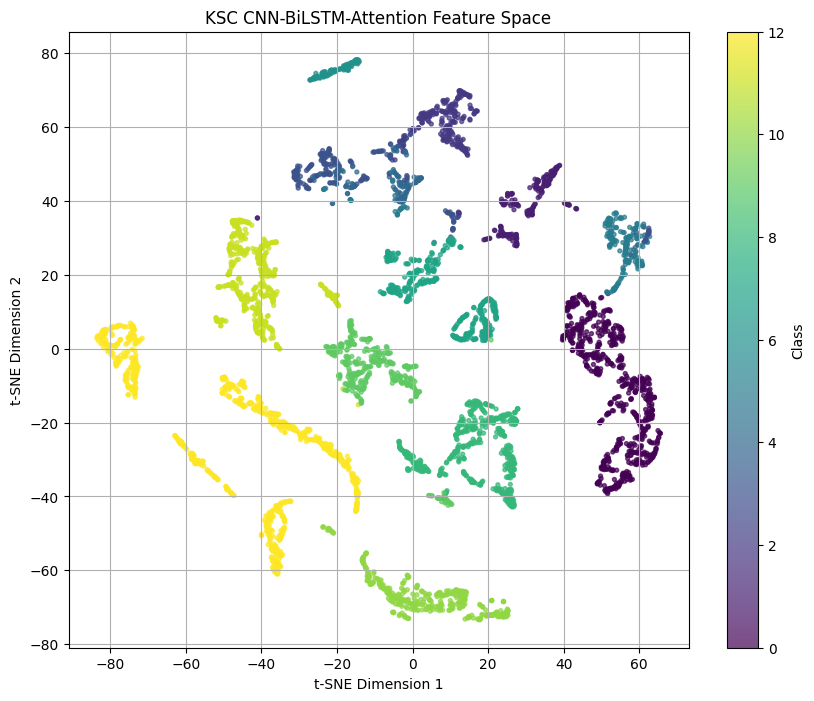

In [53]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    features_2d[:, 0],
    features_2d[:, 1],
    c=feature_labels,
    s=8,
    alpha=0.7
)

plt.title(
    "KSC CNN-BiLSTM-Attention Feature Space"
)

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

plt.colorbar(
    scatter,
    label="Class"
)

plt.grid(True)

plt.show()

In [54]:
mean_attention = attention_weights.mean(
    axis=0
).squeeze()

print(
    "Mean attention shape:",
    mean_attention.shape
)

Mean attention shape: (30,)


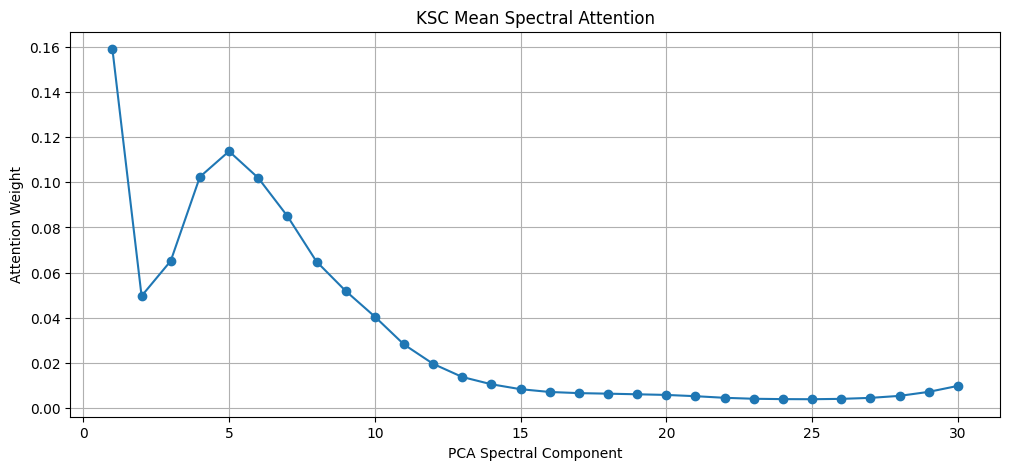

In [55]:
plt.figure(figsize=(12, 5))

plt.plot(
    np.arange(1, 31),
    mean_attention,
    marker="o"
)

plt.xlabel(
    "PCA Spectral Component"
)

plt.ylabel(
    "Attention Weight"
)

plt.title(
    "KSC Mean Spectral Attention"
)

plt.grid(True)

plt.show()

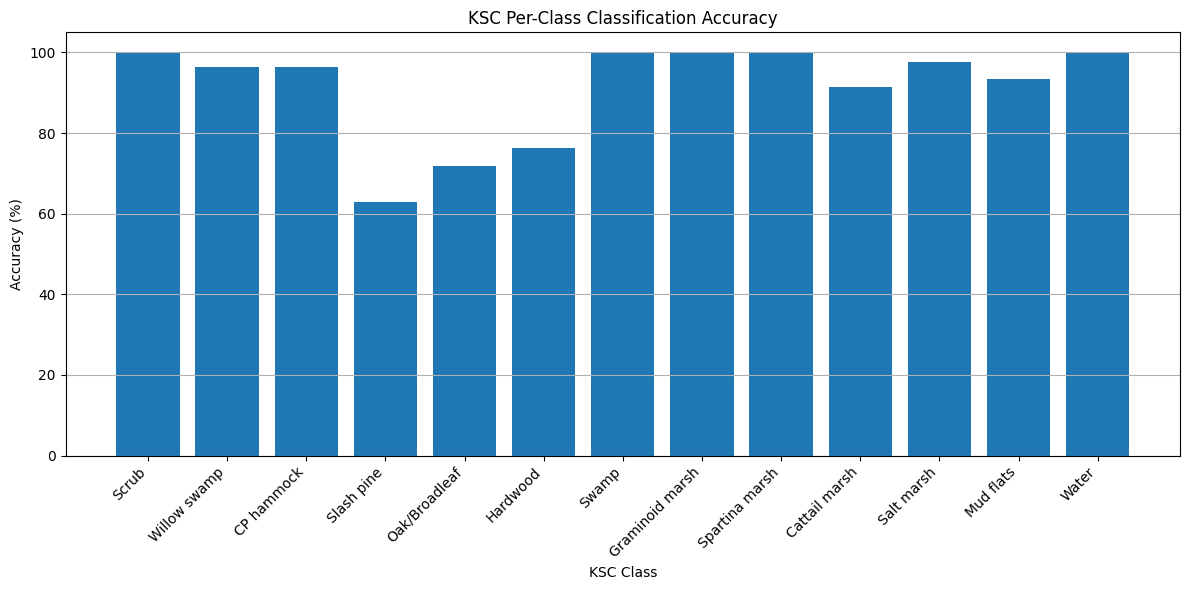

In [56]:
class_names = [
    "Scrub",
    "Willow swamp",
    "CP hammock",
    "Slash pine",
    "Oak/Broadleaf",
    "Hardwood",
    "Swamp",
    "Graminoid marsh",
    "Spartina marsh",
    "Cattail marsh",
    "Salt marsh",
    "Mud flats",
    "Water"
]

plt.figure(figsize=(12, 6))

plt.bar(
    class_names,
    class_accuracy * 100
)

plt.ylabel("Accuracy (%)")
plt.xlabel("KSC Class")

plt.title(
    "KSC Per-Class Classification Accuracy"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y"
)

plt.tight_layout()

plt.show()

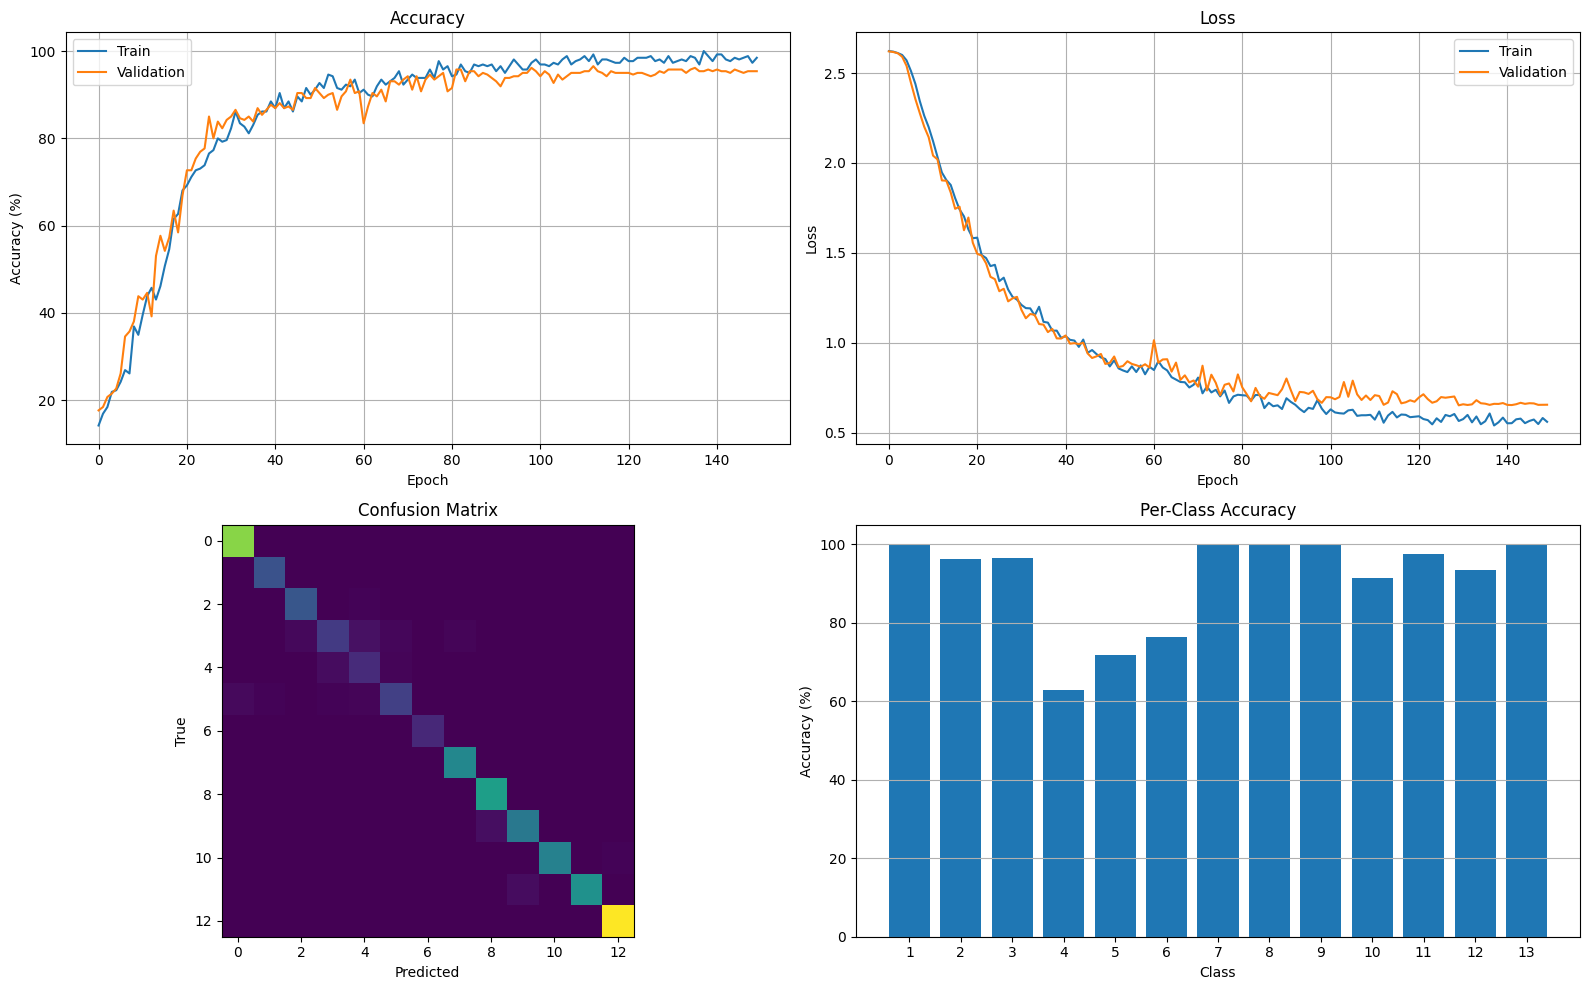

In [57]:
fig = plt.figure(
    figsize=(16, 10)
)

ax1 = fig.add_subplot(2, 2, 1)

ax1.plot(
    np.array(history["train_accuracy"]) * 100,
    label="Train"
)

ax1.plot(
    np.array(history["val_accuracy"]) * 100,
    label="Validation"
)

ax1.set_title("Accuracy")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy (%)")
ax1.legend()
ax1.grid(True)


ax2 = fig.add_subplot(2, 2, 2)

ax2.plot(
    history["train_loss"],
    label="Train"
)

ax2.plot(
    history["val_loss"],
    label="Validation"
)

ax2.set_title("Loss")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.legend()
ax2.grid(True)


ax3 = fig.add_subplot(2, 2, 3)

ax3.imshow(
    cm,
    interpolation="nearest"
)

ax3.set_title("Confusion Matrix")
ax3.set_xlabel("Predicted")
ax3.set_ylabel("True")


ax4 = fig.add_subplot(2, 2, 4)

ax4.bar(
    range(1, 14),
    class_accuracy * 100
)

ax4.set_title("Per-Class Accuracy")
ax4.set_xlabel("Class")
ax4.set_ylabel("Accuracy (%)")

ax4.set_xticks(
    range(1, 14)
)

ax4.grid(
    axis="y"
)

plt.tight_layout()

dashboard_path = (
    "/kaggle/working/"
    "ksc_dashboard.png"
)

plt.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

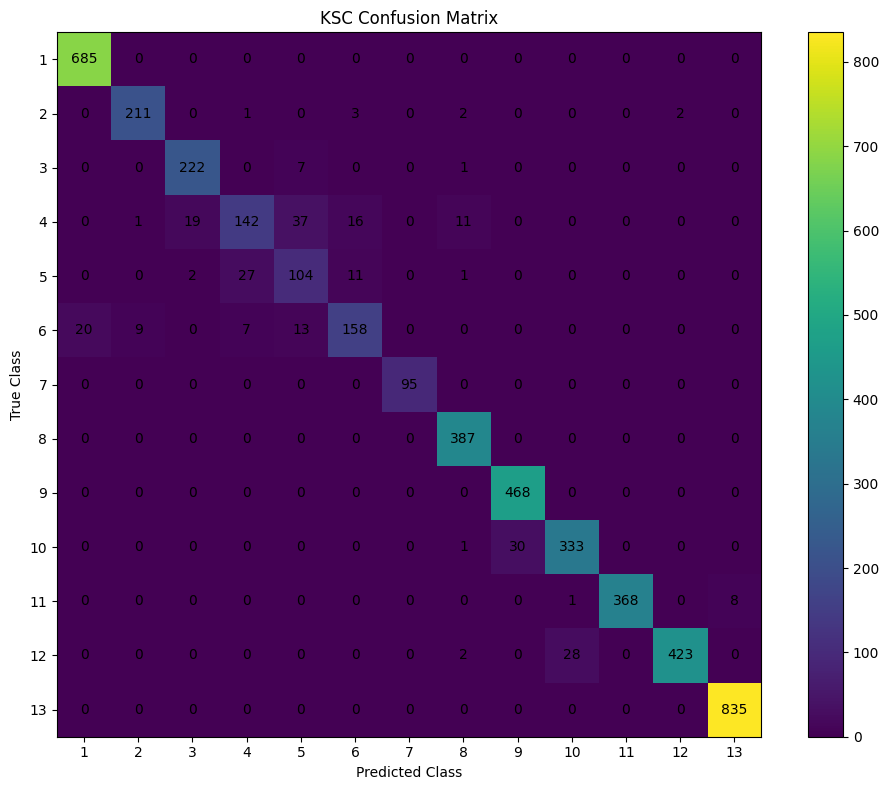

In [58]:
cm_path = (
    "/kaggle/working/"
    "ksc_confusion_matrix.png"
)

plt.figure(figsize=(10, 8))

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    "KSC Confusion Matrix"
)

plt.colorbar()

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(
    range(13),
    range(1, 14)
)

plt.yticks(
    range(13),
    range(1, 14)
)

for i in range(13):

    for j in range(13):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

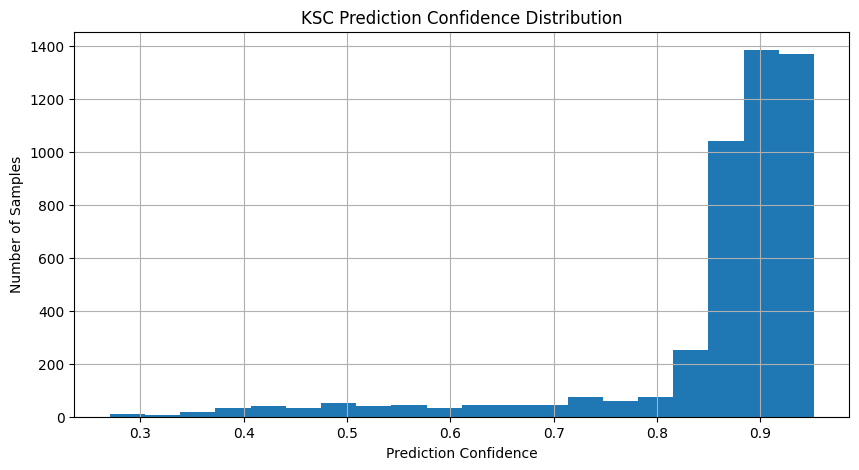

In [59]:
confidence_path = (
    "/kaggle/working/"
    "ksc_confidence_histogram.png"
)

plt.figure(figsize=(10, 5))

plt.hist(
    confidence,
    bins=20
)

plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Samples")

plt.title(
    "KSC Prediction Confidence Distribution"
)

plt.grid(True)

plt.savefig(
    confidence_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

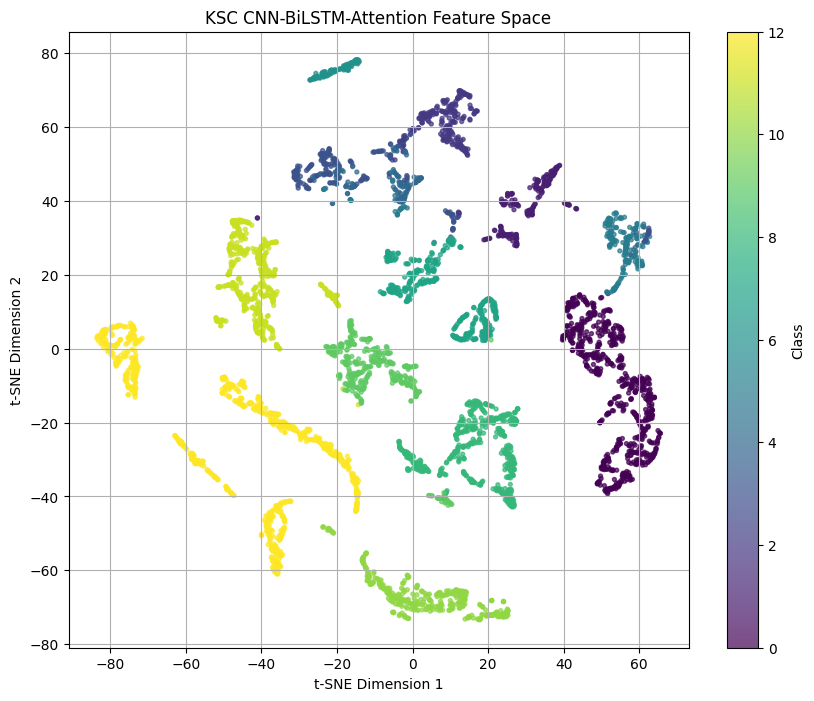

In [60]:
tsne_path = (
    "/kaggle/working/"
    "ksc_tsne_features.png"
)

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    features_2d[:, 0],
    features_2d[:, 1],
    c=feature_labels,
    s=8,
    alpha=0.7
)

plt.title(
    "KSC CNN-BiLSTM-Attention Feature Space"
)

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

plt.colorbar(
    scatter,
    label="Class"
)

plt.grid(True)

plt.savefig(
    tsne_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

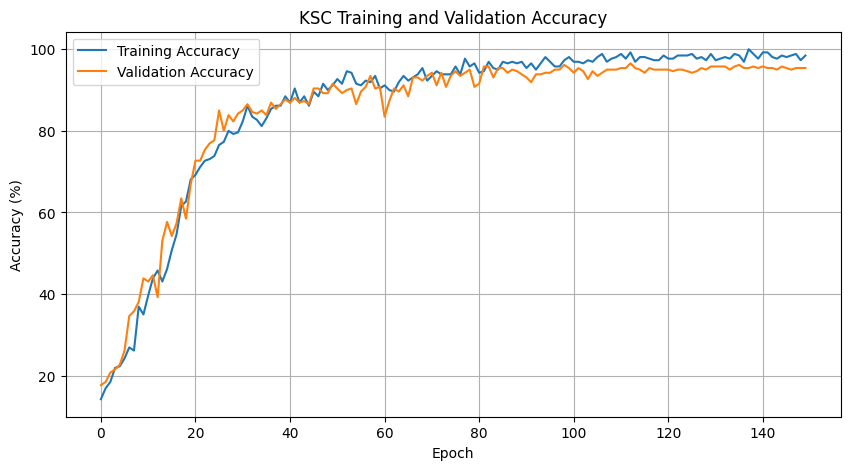

In [61]:
accuracy_curve_path = (
    "/kaggle/working/"
    "ksc_accuracy_curve.png"
)

plt.figure(figsize=(10, 5))

plt.plot(
    np.array(history["train_accuracy"]) * 100,
    label="Training Accuracy"
)

plt.plot(
    np.array(history["val_accuracy"]) * 100,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "KSC Training and Validation Accuracy"
)

plt.legend()
plt.grid(True)

plt.savefig(
    accuracy_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

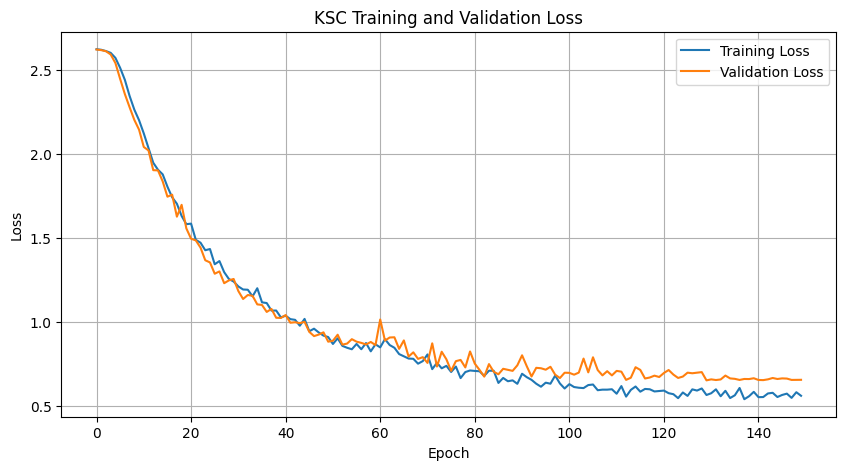

In [62]:
loss_curve_path = (
    "/kaggle/working/"
    "ksc_loss_curve.png"
)

plt.figure(figsize=(10, 5))

plt.plot(
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "KSC Training and Validation Loss"
)

plt.legend()
plt.grid(True)

plt.savefig(
    loss_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

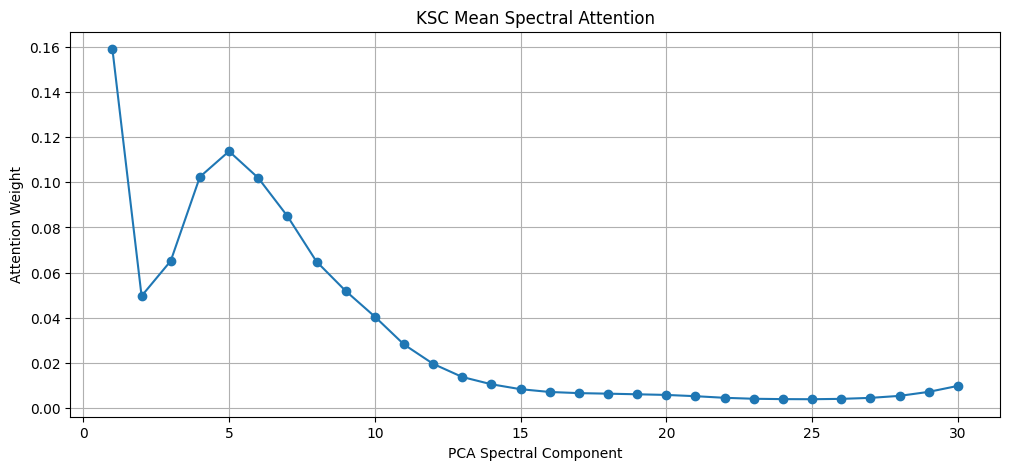

In [63]:
attention_path = (
    "/kaggle/working/"
    "ksc_spectral_attention.png"
)

plt.figure(figsize=(12, 5))

plt.plot(
    np.arange(1, 31),
    mean_attention,
    marker="o"
)

plt.xlabel(
    "PCA Spectral Component"
)

plt.ylabel(
    "Attention Weight"
)

plt.title(
    "KSC Mean Spectral Attention"
)

plt.grid(True)

plt.savefig(
    attention_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [64]:
summary_path = (
    "/kaggle/working/"
    "ksc_training_summary.txt"
)

with open(
    summary_path,
    "w"
) as f:

    f.write(
        "KSC CNN-BiLSTM-Attention "
        "Training Summary\n"
    )

    f.write("=" * 60 + "\n")

    f.write(
        f"Dataset: KSC\n"
    )

    f.write(
        f"Input Shape: "
        f"9 x 9 x 30\n"
    )

    f.write(
        f"Number of Classes: 13\n"
    )

    f.write(
        f"Train Samples: "
        f"{len(y_train)}\n"
    )

    f.write(
        f"Validation Samples: "
        f"{len(y_val)}\n"
    )

    f.write(
        f"Test Samples: "
        f"{len(y_test)}\n"
    )

    f.write(
        f"Best Epoch: "
        f"{best_epoch}\n"
    )

    f.write(
        f"Overall Accuracy: "
        f"{oa * 100:.4f}%\n"
    )

    f.write(
        f"Average Accuracy: "
        f"{aa * 100:.4f}%\n"
    )

    f.write(
        f"Macro Precision: "
        f"{precision:.4f}\n"
    )

    f.write(
        f"Macro Recall: "
        f"{recall:.4f}\n"
    )

    f.write(
        f"Macro F1: "
        f"{macro_f1:.4f}\n"
    )

    f.write(
        f"Cohen Kappa: "
        f"{kappa:.4f}\n"
    )

print("Summary saved:", summary_path)

Summary saved: /kaggle/working/ksc_training_summary.txt


In [65]:
print("=" * 70)
print("KSC EXPERIMENT OUTPUTS")
print("=" * 70)

output_files = [
    checkpoint_path,
    history_path,
    report_path,
    metrics_path,
    dashboard_path,
    cm_path,
    confidence_path,
    tsne_path,
    accuracy_curve_path,
    loss_curve_path,
    attention_path,
    summary_path
]

for path in output_files:

    exists = os.path.exists(path)

    print(
        f"{'✓' if exists else '✗'} "
        f"{os.path.basename(path)}"
    )

KSC EXPERIMENT OUTPUTS
✓ ksc_best_checkpoint.pth
✓ ksc_training_history.csv
✓ ksc_classification_report.txt
✓ ksc_metrics.csv
✓ ksc_dashboard.png
✓ ksc_confusion_matrix.png
✓ ksc_confidence_histogram.png
✓ ksc_tsne_features.png
✓ ksc_accuracy_curve.png
✓ ksc_loss_curve.png
✓ ksc_spectral_attention.png
✓ ksc_training_summary.txt


In [66]:
print("\n")
print("=" * 70)
print("FINAL KSC CNN-BiLSTM-ATTENTION RESULTS")
print("=" * 70)

print(
    f"Overall Accuracy : {oa * 100:.2f}%"
)

print(
    f"Average Accuracy : {aa * 100:.2f}%"
)

print(
    f"Macro Precision  : {precision:.4f}"
)

print(
    f"Macro Recall     : {recall:.4f}"
)

print(
    f"Macro F1         : {macro_f1:.4f}"
)

print(
    f"Cohen Kappa      : {kappa:.4f}"
)

print(
    f"Best Epoch       : {best_epoch}"
)

print("=" * 70)
print("KSC EXPERIMENT COMPLETED")
print("=" * 70)



FINAL KSC CNN-BiLSTM-ATTENTION RESULTS
Overall Accuracy : 94.46%
Average Accuracy : 91.25%
Macro Precision  : 0.9177
Macro Recall     : 0.9125
Macro F1         : 0.9137
Cohen Kappa      : 0.9382
Best Epoch       : 130
KSC EXPERIMENT COMPLETED
